# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Укажите устройство, выбранную ветку, использованные внешние источники и нерешённые задачи (если есть).

In [2]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.14.1
CUDA available:  False
MPS available:   True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='mps')

In [251]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = set(['7.1', '7.2', '7.3', '7.4', '7.5'])        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [5]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [6]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [7]:
B, C_in, H, W = 10, 16, 32, 32
C_out = 8
kh, kw = 3, 3
groups = 2

x = torch.rand((B, C_in, H, W))
weight = torch.rand((C_out, C_in // groups, kh, kw))

# x = x.reshape((B, groups, C_in // groups, H, W))
# x.shape
x = F.unfold(x, kernel_size=(kh, kw))
x = x.reshape((B, groups, C_in // groups * kh * kw, -1))

res = torch.matmul(weight.reshape(groups, C_out // groups, -1), x)
res = res.reshape((B, C_out, -1))

res = F.fold(res, conv_output_shape((H, W), (kh, kw)), kernel_size=(1, 1))
res.shape

torch.Size([10, 8, 30, 30])

In [8]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape

    x = F.unfold(x, kernel_size=(kh, kw), stride=stride, padding=padding, dilation=dilation)
    x = x.reshape((B, groups, C_in // groups * kh * kw, -1))
    x = torch.matmul(weight.reshape(groups, C_out // groups, -1), x)
    x = x.reshape((B, C_out, -1))
    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride=stride, padding=padding, dilation=dilation)
    x = x.reshape(B, C_out, H_out, W_out)

    if bias is not None:
        x += bias[None, :, None, None]
    
    return x

In [9]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [10]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.** 

В im2col расход дополнительной памяти на операцию растет со скоростью $k^2$ (при нечетных k и padding = k // 2 в точности так растет), что на больших ядрах приводит к огромным затратам памяти. В FFT-свертке такого нет, в ней память может быть большой, но нет такой сильной зависимости именно от размера ядра, по-этому она предпочтительнее на больших ядрах.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [11]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding

        B, _, H, W = x.shape
        C_out, _, kh, kw = weight.shape
        H_out, W_out = grad_out.shape[-2:]

        grad_b = torch.sum(grad_out, dim=(0, 2, 3)) if ctx.needs_input_grad[2] else None
        x_unfold = F.unfold(x, (kh, kw), stride=s, padding=p)
        grad_out_flat = grad_out.reshape(B, C_out, -1)
        grad_w = torch.matmul(grad_out_flat, x_unfold.transpose(1, 2))
        grad_w = grad_w.sum(dim=0).reshape_as(weight)

        op_h = H - ((H_out - 1) * s - 2 * p + kh)
        op_w = W - ((W_out - 1) * s - 2 * p + kw)
        grad_x = F.conv_transpose2d(
            grad_out, weight, stride=s, padding=p, output_padding=(op_h, op_w)
        )

        return grad_x, grad_w, grad_b, None, None

In [12]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** 

1. $H=7$ и `output_padding` = 0
2. $H=8$ и `output_padding` = 1

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [15]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [50]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)

    output = model(x)
    o_shape = output.shape
    loss = output[:, :, (o_shape[2] - 1) // 2 + 1, (o_shape[3] - 1) // 2 + 1].sum()
    loss.backward()

    mask = x.grad.sum(dim=(0, 1)) != 0
    x, y = torch.meshgrid(torch.arange(size), torch.arange(size))
    min_x, max_x, min_y, max_y = x[mask].min().item(), x[mask].max().item(), y[mask].min().item(), y[mask].max().item()
    
    return max_x - min_x + 1, max_y - min_y + 1

In [51]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** 

Основная причина в том, что цель эксперимента - вычислить RF, а для этого нам надо понять какие пиксели афектят на центр итоговой карты (features map). А какие-то необычные свертки (например с нулевыми весами где-то) или нелинейности (особенно ReLU - она очень хорошо убивает градиент) могут отрубить градиент у пикселей каких-то, но это не будет значить, что финальные признаки "не смотрят" на писклеть где градиент 0, мы как-бы строим систему так, что g=0 <=> пиксель не влияет. C MaxPool такая же история - он оставляет градиент только по максимальному пикселю, но в нашем случае на размер RF он не повлиял.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [108]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    x = torch.randn(n_inputs, in_channels, size, size, requires_grad=True)

    output = model(x)
    o_shape = output.shape
    loss = output[:, :, o_shape[2] // 2, o_shape[3] // 2].sum()
    loss.backward()

    influence = x.grad.abs().mean(dim=0).sum(dim=(0, 2))
    influence /= influence.sum()
    rows = torch.arange(size, device=influence.device, dtype=influence.dtype)
    mean = (rows * influence).sum()
    variance = ((rows - mean).square() * influence).sum()
    
    return variance.sqrt().item()

In [109]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [110]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


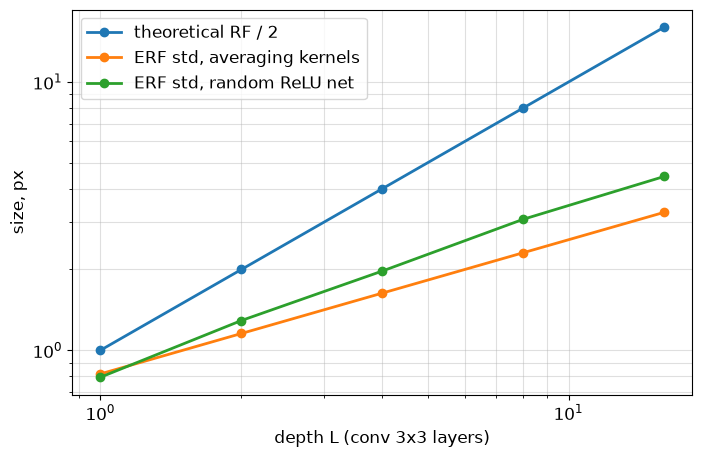

In [113]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** 

С глубиной эффективный RF занимает всё меньшую долю теоретического: для усредняющей сети их размеры растут как $\sqrt{L}$ и $L$ соответственно, поэтому наклоны на log-log графике равны примерно $0.5$ и $1$. Отношение эффективного RF к теоретическому убывает как $L^{-1/2}$.

В эксперименте случайная сеть с ReLU при $L \geq 2$ имеет больший ERF std, чем усредняющая: например, при $L = 16$ получено $4.44$ против $3.27$. Её эффективный RF также растёт медленнее теоретического.

Различие связано с изменением распределения градиента в случайной многоканальной сети. Поскольку одновременно изменились веса, число каналов и наличие ReLU, этот эксперимент не позволяет выделить вклад одной только ReLU.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [138]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum

        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        
        self.running_mean = nn.Buffer(torch.zeros(num_features))
        self.running_var = nn.Buffer(torch.ones(num_features))
        self.register_buffer(
            "num_batches_tracked",
            torch.tensor(0, dtype=torch.long),
        )

    def forward(self, x):
        n = x.shape[0] * x.shape[2] * x.shape[3]
        
        if self.training:
            mean = torch.mean(x, dim=(0, 2, 3))
            var = torch.var(x, dim=(0, 2, 3), correction=0)
        else:
            mean = self.running_mean
            var = self.running_var

        result = (
            self.weight.reshape((1, -1, 1, 1)) *
            (x - mean.reshape((1, -1, 1, 1))) / torch.sqrt(var.reshape((1, -1, 1, 1)) + self.eps)
            + self.bias.reshape((1, -1, 1, 1))
        )

        if self.training:
            with torch.no_grad():
                self.running_mean = self.momentum * mean + (1 - self.momentum) * self.running_mean
                self.running_var = self.momentum * n / (n - 1) * var + (1 - self.momentum) * self.running_var
                self.num_batches_tracked += 1

        return result

In [139]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** 

Идея в следующем:
- На моменте нормировки батча мы хотим, чтобы выборочное среднее и дисперсия были равны 0 и 1 (до домножения на обучаемые веса).
- Вычисление среднего (running буферы) мы делаем чтобы оценить дисперсии и среднии генеральной совокупности, в такой формулировке один батч - это уже какая-то подвыборка и с точки зрения статистики в такой задаче лучше брать несмещенную дисперсию, чтобы оценка была тоже несмещенной.

Рассмотрим на примерах:
1. B = 4, kernel = (5, 5) - отличие в $\frac{100}{99}$ раз.
2. B = 2, kerner = (1, 1) - отличие в $2$ раза.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.**

Для выходного канала $o$ обозначим результат свёртки через $z_o = W_o * x + b_o$. В режиме `eval()` статистики BatchNorm фиксированы, поэтому

$$
y_o = \gamma_o\frac{W_o*x+b_o-\hat\mu_o}{\sqrt{\hat\sigma_o^2+\varepsilon}}+\beta_o.
$$

Введём $a_o=\gamma_o/\sqrt{\hat\sigma_o^2+\varepsilon}$ и раскроем скобки:

$$
y_o=(a_o W_o)*x+\bigl(a_o(b_o-\hat\mu_o)+\beta_o\bigr).
$$

Следовательно,

$$
W'_o=a_o W_o,\qquad b'_o=a_o(b_o-\hat\mu_o)+\beta_o.
$$

Множитель $a_o$ применяется ко всем весам соответствующего выходного канала. Если у исходной свёртки нет bias, берём $b_o=0$; у объединённой свёртки bias в общем случае появляется. Для групповой свёртки формулы те же.


In [140]:
import copy


@torch.no_grad()
def fuse_conv_bn(conv: nn.Conv2d, bn: nn.BatchNorm2d) -> nn.Conv2d:
    if conv.training or bn.training:
        raise ValueError("Both modules must be in eval mode")
    if not bn.affine or not bn.track_running_stats:
        raise ValueError("BatchNorm must have affine parameters and running statistics")
    if conv.out_channels != bn.num_features:
        raise ValueError("Convolution and BatchNorm channels must match")

    fused = copy.deepcopy(conv)
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    bias = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)
    fused.weight.copy_((conv.weight * scale[:, None, None, None]).to(conv.weight))
    fused.bias = nn.Parameter(
        (scale * (bias - bn.running_mean) + bn.bias).to(conv.weight)
    )
    return fused


def fuse_sequential(seq: nn.Sequential) -> nn.Sequential:
    if any(module.training for module in seq.modules()):
        raise ValueError("The sequential model must be in eval mode")

    modules = list(seq.children())
    fused_modules: list[nn.Module] = []
    index = 0
    while index < len(modules):
        if (
            isinstance(modules[index], nn.Conv2d)
            and index + 1 < len(modules)
            and isinstance(modules[index + 1], nn.BatchNorm2d)
        ):
            fused_modules.append(fuse_conv_bn(modules[index], modules[index + 1]))
            index += 2
        else:
            fused_modules.append(copy.deepcopy(modules[index]))
            index += 1
    return nn.Sequential(*fused_modules).eval()


In [141]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [142]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [143]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 58.0 ms   fused: 56.4 ms   speedup 1.03x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.**

В `eval()` BatchNorm использует фиксированные running-статистики и является поканальным аффинным преобразованием, которое можно включить в веса и bias свёртки. В `train()` среднее и дисперсия зависят от текущего батча, поэтому одной свёрткой с фиксированными весами нельзя заменить Conv + BN для произвольного входа; кроме того, BN обновляет свои running-статистики.

Слияние убирает отдельное вычисление BatchNorm и связанные с ним чтение и запись промежуточных данных. Выигрыш зависит от устройства, размеров тензоров, реализации свёртки и доступных оптимизаций: если почти всё время занимает свёртка либо backend уже объединяет операции, ускорение может быть небольшим.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** 

Для ReLU при симметричном относительно нуля распределении $h^{\text{prev}}$ имеем $\mathbb E[h^{\text{prev}}_i]=0$ и $\mathbb E[\mathrm{ReLU}(h^{\text{prev}}_i)^2]=\frac12\mathrm{Var}(h^{\text{prev}}_i)$. Поэтому

$$
\mathrm{Var}(h_i)=\frac{nv}{2}\mathrm{Var}(h^{\text{prev}}_i).
$$

Чтобы дисперсия сохранялась от слоя к слою, нужно $nv/2=1$, то есть **$v=2/n$**.

Для $\tanh$ в линейном режиме $\tanh(h)\approx h$. При нулевом среднем получаем

$$
\mathrm{Var}(h_i)\approx nv\,\mathrm{Var}(h^{\text{prev}}_i).
$$

Следовательно, дисперсия приблизительно сохраняется при **$v=1/n$**. Это приближение применимо, пока значения находятся в области, где $\tanh$ близок к линейной функции.

При стандартной инициализации $W_{ij}\sim\mathcal U(-1/\sqrt n,\,1/\sqrt n)$ дисперсия весов равна

$$
v=\frac{(2/\sqrt n)^2}{12}=\frac{1}{3n}.
$$

Для ReLU множитель изменения дисперсии между слоями составляет $nv/2=1/6$. Следовательно, дисперсия уменьшается в 6 раз, а стандартное отклонение — в $\sqrt6\approx2.45$ раза за слой:

$$
\frac{\mathrm{std}(h^{(l)})}{\mathrm{std}(h^{(l-1)})}
=\frac{1}{\sqrt6}\approx0.408.
$$

In [150]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


@torch.no_grad()
def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    x = torch.randn(n, width)
    stds = []

    for _ in range(depth):
        weight = torch.empty(width, width)
        init(weight)
        x = act(nn.functional.linear(x, weight))
        stds.append(x.std().item())

    return stds


In [151]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.758


np.float64(0.40910241812972786)

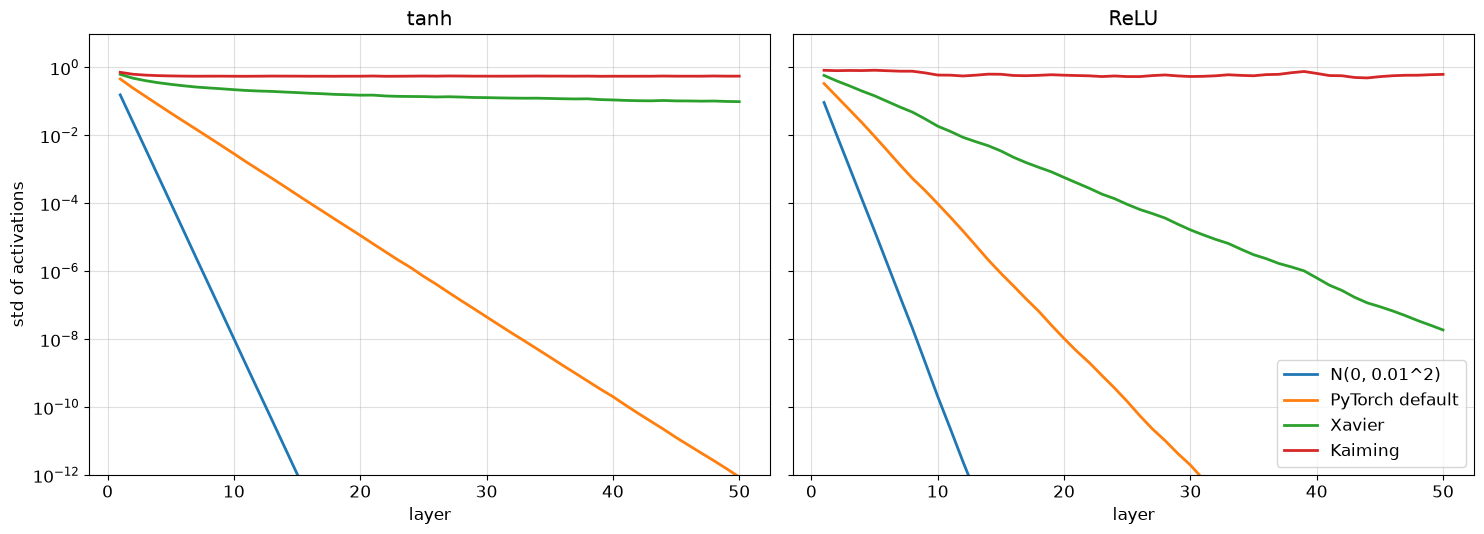

In [152]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** 

В этом эксперименте масштаб активаций лучше всего сохраняют Kaiming + ReLU и Kaiming + tanh: за 50 слоёв std меняется с 0.827 до 0.627 и с 0.721 до 0.557 соответственно. Xavier + tanh даёт более заметное затухание - с 0.628 до 0.099; сохранение дисперсии для этой пары ожидалось только в линейном режиме tanh.

Остальные сочетания приводят к сильному затуханию. В частности, для стандартной инициализации PyTorch с ReLU средний множитель std за слой равен 0.409, что близко к теоретическому $1/\sqrt{6}\approx0.408$. Сохранение масштаба активаций само по себе не гарантирует сохранения масштаба градиентов.

ResNet отличается от исследованной цепочки Linear + активация: BatchNorm нормирует сигнал, а остаточные соединения дают ему и градиентам дополнительный путь через блоки. Поэтому затухание, наблюдаемое в глубокой MLP без нормализации и shortcut-соединений, не переносится напрямую на ResNet со стандартной инициализацией.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [162]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue

                p.add_(-group['weight_decay'] * group['lr'] * p)
                
                state = self.state[p]
                if not state:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)

                state['step'] += 1
                state['exp_avg'] = beta1 * state['exp_avg'] + (1 - beta1) * p.grad
                state['exp_avg_sq'] = beta2 * state['exp_avg_sq'] + (1 - beta2) * p.grad ** 2

                if group['bias_correction']:
                    m_hat = state['exp_avg'] / (1 - np.pow(beta1, state['step']))
                    v_hat = state['exp_avg_sq'] / (1 - np.pow(beta2, state['step']))
                else:
                    m_hat = state['exp_avg']
                    v_hat = state['exp_avg_sq']

                p.add_(-group['lr'] * m_hat / (torch.sqrt(v_hat) + group['eps']))

In [163]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [164]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


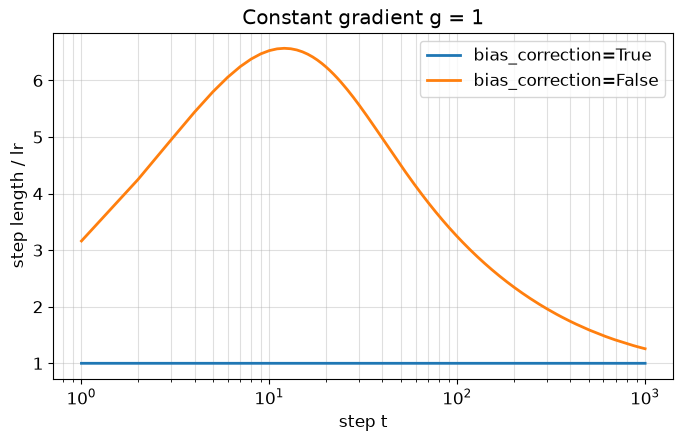

In [165]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** 

При постоянном градиенте $g_t=1$ и нулевых начальных моментах получаем $m_t=1-\beta_1^t$ и $v_t=1-\beta_2^t$. Поэтому без bias correction и при `weight_decay=0` длина шага равна

$$
|\Delta\theta_t|=\mathrm{lr}\,\frac{1-\beta_1^t}{\sqrt{1-\beta_2^t}+\varepsilon}.
$$

В начале обучения шаг может существенно превышать заданный learning rate: например, при $\beta_1=0.9$, $\beta_2=0.999$ на первом шаге он составляет примерно $3.16\,\mathrm{lr}$, если пренебречь $\varepsilon$. Такие большие обновления могут приводить к перескакиванию через минимум и нестабильности обучения. При больших $t$ множитель стремится к $1/(1+\varepsilon)\approx1$, и длина шага приближается к `lr`.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [166]:
def cosine_lr(step, total_steps, min_ratio=0.0):

    return (
        min_ratio + 
        (1 - min_ratio) * (1 + np.cos(np.pi * min(1, step / total_steps))) / 2
    )

In [167]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

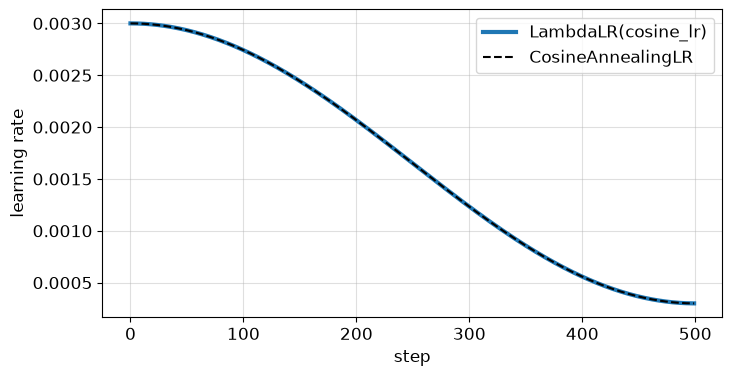

In [168]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** 

К концу обучения мы рассчитываем приблизиться к локальному минимуму, а если мы не будем уменьшать шаг стохастического градиентного спуска, при постоянном шаге и сохраняющемся шуме градиента параметры обычно не сходятся точно к минимуму, а колеблются вокруг него. Во-первых, даже если общий градиент равен нулю при каких-то параметрах - это совсем не значит что также будет на всех батчах, во-вторых адаптивность Adam не гарантирует, что размер шага будет уменьшаться.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [178]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='mps:0'),
 tensor([0.2470, 0.2435, 0.2616], device='mps:0'))

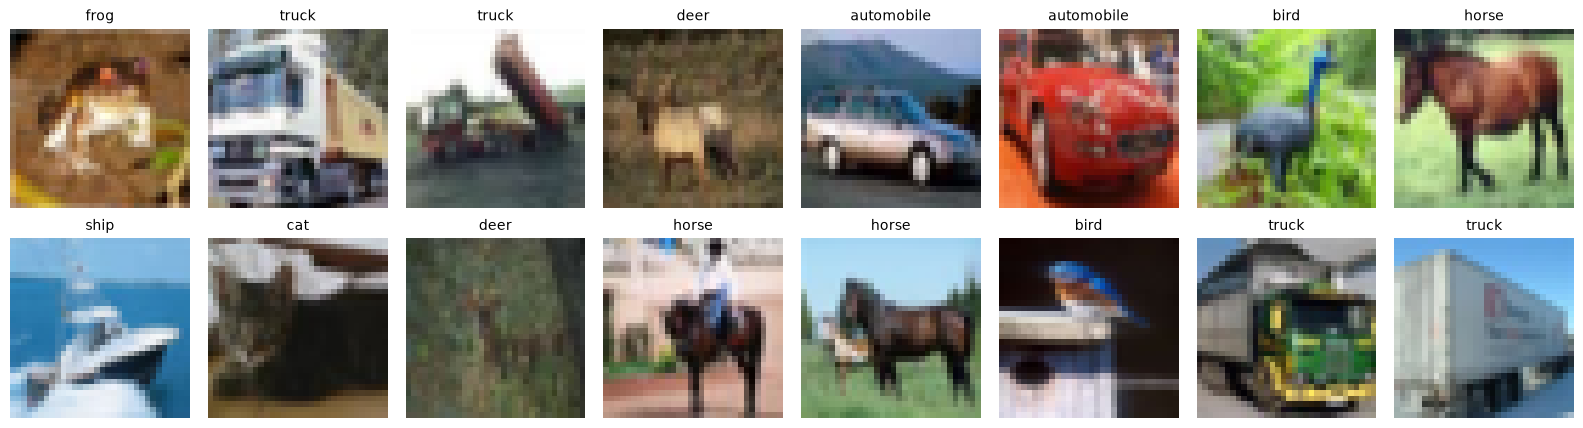

In [179]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [180]:
def conv3x3(
    c_in: int,
    c_out: int,
    stride: int = 1,
    separable: bool = False,
) -> nn.Module:
    if separable:
        return nn.Sequential(
            nn.Conv2d(
                c_in, c_in, 3,
                stride=stride, padding=1, groups=c_in, bias=False,
            ),
            nn.Conv2d(c_in, c_out, 1, bias=False),
        )
    return nn.Conv2d(
        c_in, c_out, 3, stride=stride, padding=1, bias=False,
    )


class Block(nn.Module):
    def __init__(
        self,
        c_in: int,
        c_out: int,
        stride: int = 1,
        residual: bool = True,
        separable: bool = False,
    ):
        super().__init__()
        self.residual = residual
        self.layers = nn.Sequential(
            conv3x3(c_in, c_out, stride, separable),
            nn.BatchNorm2d(c_out),
            nn.ReLU(),
            conv3x3(c_out, c_out, separable=separable),
            nn.BatchNorm2d(c_out),
        )
        self.relu = nn.ReLU()

        if residual:
            if stride != 1 or c_in != c_out:
                self.shortcut = nn.Sequential(
                    nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                    nn.BatchNorm2d(c_out),
                )
            else:
                self.shortcut = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.layers(x)
        if self.residual:
            out = out + self.shortcut(x)
        return self.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(
        self,
        depth: int = 20,
        residual: bool = True,
        separable: bool = False,
        widths: tuple[int, int, int] = (16, 32, 64),
        n_classes: int = 10,
    ):
        super().__init__()
        assert depth >= 8 and (depth - 2) % 6 == 0
        assert len(widths) == 3
        n_blocks = (depth - 2) // 6

        self.stem = nn.Sequential(
            conv3x3(3, widths[0]),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(),
        )

        stages = []
        c_in = widths[0]
        for stage_index, c_out in enumerate(widths):
            blocks = []
            for block_index in range(n_blocks):
                stride = 2 if stage_index > 0 and block_index == 0 else 1
                blocks.append(
                    Block(c_in, c_out, stride, residual, separable)
                )
                c_in = c_out
            stages.append(nn.Sequential(*blocks))

        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        x = self.stages(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)

In [181]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [182]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(
    model: nn.Module,
    epochs: int,
    lr: float,
    weight_decay: float = 0.05,
    batch_size: int = 256,
    log: bool = True,
) -> dict[str, list[float]]:
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()

    groups = [
        {
            "params": [p for p in model.parameters() if p.ndim > 1],
            "weight_decay": weight_decay,
        },
        {
            "params": [p for p in model.parameters() if p.ndim <= 1],
            "weight_decay": 0.0,
        },
    ]
    optimizer = MyAdamW(groups, lr=lr)
    steps_per_epoch = (len(X_train) + batch_size - 1) // batch_size
    total_steps = epochs * steps_per_epoch
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=lambda step: cosine_lr(step, total_steps, min_ratio=0.0),
    )

    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0

        for x, y in iterate_batches(
            X_train,
            Y_train,
            batch_size,
            shuffle=True,
            transform=normalize,
        ):
            optimizer.zero_grad()
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()
            scheduler.step()

            loss_sum += loss.item() * len(y)

        train_loss = loss_sum / len(X_train)
        test_logits = predict_logits(
            model,
            X_test,
            batch_size=batch_size,
            transform=normalize,
        )
        test_acc = accuracy(test_logits, Y_test)

        history["train_loss"].append(train_loss)
        history["test_acc"].append(test_acc)

        if log:
            elapsed = time.time() - start
            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"loss: {train_loss:.4f} | "
                f"test acc: {test_acc:.4f} | "
                f"lr: {scheduler.get_last_lr()[0]:.6f} | "
                f"time: {elapsed:.1f}s"
            )

    return history

In [183]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

Epoch 1/20 | loss: 1.4360 | test acc: 0.5066 | lr: 0.002982 | time: 9.7s
Epoch 2/20 | loss: 0.9729 | test acc: 0.6192 | lr: 0.002927 | time: 19.0s
Epoch 3/20 | loss: 0.7759 | test acc: 0.5508 | lr: 0.002837 | time: 28.3s
Epoch 4/20 | loss: 0.6561 | test acc: 0.7267 | lr: 0.002714 | time: 38.5s
Epoch 5/20 | loss: 0.5659 | test acc: 0.7122 | lr: 0.002561 | time: 48.5s
Epoch 6/20 | loss: 0.4984 | test acc: 0.7874 | lr: 0.002382 | time: 60.1s
Epoch 7/20 | loss: 0.4394 | test acc: 0.7482 | lr: 0.002181 | time: 72.4s
Epoch 8/20 | loss: 0.3890 | test acc: 0.7926 | lr: 0.001964 | time: 83.9s
Epoch 9/20 | loss: 0.3361 | test acc: 0.7610 | lr: 0.001735 | time: 93.5s
Epoch 10/20 | loss: 0.2842 | test acc: 0.7966 | lr: 0.001500 | time: 103.3s
Epoch 11/20 | loss: 0.2252 | test acc: 0.8097 | lr: 0.001265 | time: 112.8s
Epoch 12/20 | loss: 0.1794 | test acc: 0.8195 | lr: 0.001036 | time: 122.4s
Epoch 13/20 | loss: 0.1259 | test acc: 0.8210 | lr: 0.000819 | time: 132.5s
Epoch 14/20 | loss: 0.0855 | te

{'train acc': 0.9998999834060669, 'test acc': 0.8291000127792358}

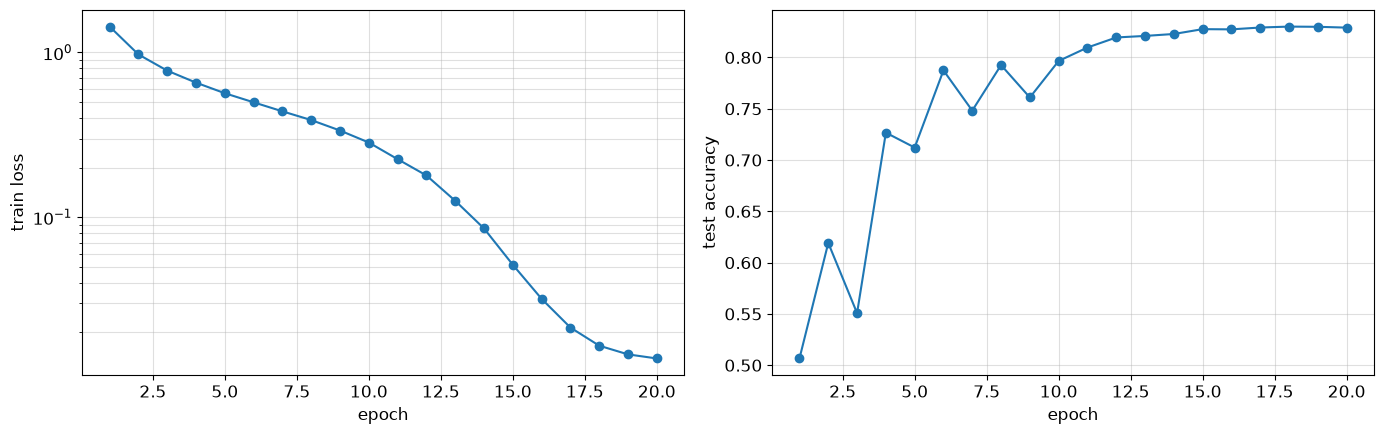

In [184]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** 

1) В конце обучения разрыв между train и test accuracy оказался достаточно высоким (~0.18), но это связано скорее с переобучением, так как на train accuracy достигла значения >0.99, а это очень много. В то же время на test accuracy около 0.82, это хороший результат, но да, сильно меньше train.
2) Train loss продалжает падать вплоть до 18-19/20 эпох, а во test accuracy перестает значительно увечиваться уже после 12-ой эпохи, но все равно он продолжает расти, хоть и медленно. Самое главное, что test accuracy не падает.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [186]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [187]:
ablation = {}

for name, config in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**config)

    print(f"\nTraining {name}")
    started = time.perf_counter()
    history = train_cifar(model, ABL_EPOCHS, LR)
    minutes = (time.perf_counter() - started) / 60

    train_logits = predict_logits(
        model,
        X_train[:10_000],
        batch_size=256,
        transform=normalize,
    )

    ablation[name] = dict(
        params=n_params(model),
        train_acc=accuracy(train_logits, Y_train[:10_000]),
        test_acc=history["test_acc"][-1],
        minutes=minutes,
        history=history,
    )

    del model, train_logits

print(
    f'{"model":<22}{"params":>9}'
    f'{"train acc":>11}{"test acc":>10}{"minutes":>9}'
)
for name, res in ablation.items():
    print(
        f'{name:<22}{res["params"]:>9,}'
        f'{res["train_acc"]:>11.4f}'
        f'{res["test_acc"]:>10.4f}'
        f'{res["minutes"]:>9.1f}'
    )

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')


Training plain-20
Epoch 1/10 | loss: 1.7046 | test acc: 0.3827 | lr: 0.002927 | time: 10.6s
Epoch 2/10 | loss: 1.2869 | test acc: 0.5064 | lr: 0.002714 | time: 19.6s
Epoch 3/10 | loss: 1.0400 | test acc: 0.5131 | lr: 0.002382 | time: 28.3s
Epoch 4/10 | loss: 0.8869 | test acc: 0.6881 | lr: 0.001964 | time: 37.2s
Epoch 5/10 | loss: 0.7572 | test acc: 0.6784 | lr: 0.001500 | time: 45.9s
Epoch 6/10 | loss: 0.6630 | test acc: 0.7319 | lr: 0.001036 | time: 54.4s
Epoch 7/10 | loss: 0.5740 | test acc: 0.7603 | lr: 0.000618 | time: 63.1s
Epoch 8/10 | loss: 0.5074 | test acc: 0.7849 | lr: 0.000286 | time: 71.7s
Epoch 9/10 | loss: 0.4563 | test acc: 0.7887 | lr: 0.000073 | time: 80.5s
Epoch 10/10 | loss: 0.4298 | test acc: 0.7895 | lr: 0.000000 | time: 89.3s

Training plain-56
Epoch 1/10 | loss: 2.0218 | test acc: 0.2098 | lr: 0.002927 | time: 23.6s
Epoch 2/10 | loss: 1.8603 | test acc: 0.2510 | lr: 0.002714 | time: 49.3s
Epoch 3/10 | loss: 1.7637 | test acc: 0.3236 | lr: 0.002382 | time: 73.5s

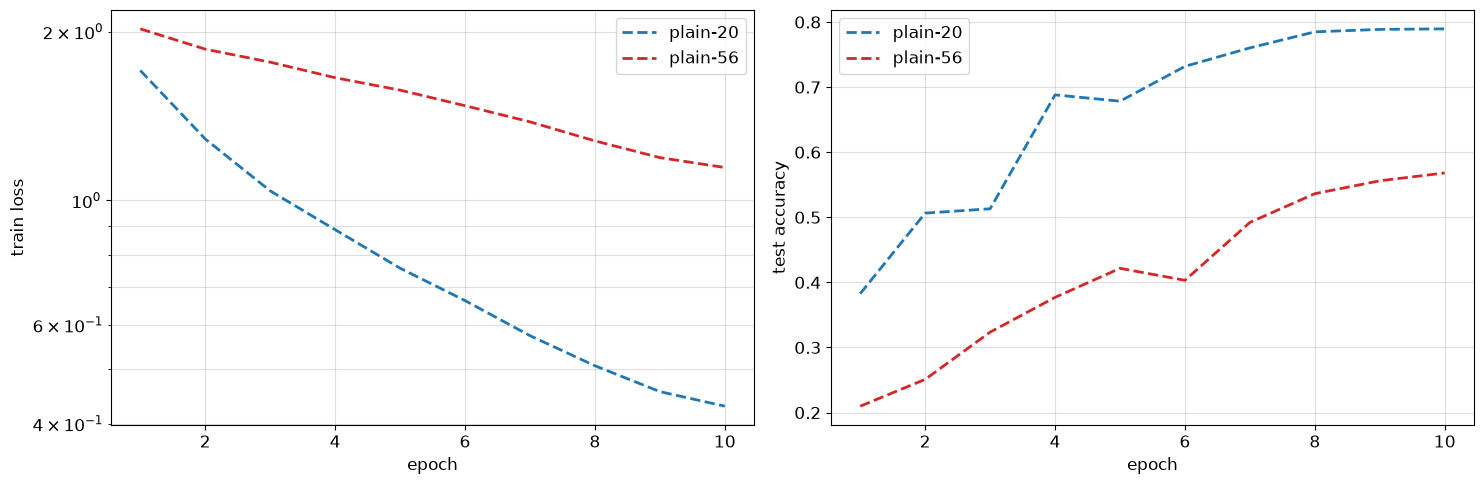

In [188]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** 

1) Явно видно **ухудшение** train loss при **увеличении глубины**. Это неудивительно, так как мы тестировали подход без residual-слоев, а они как раз и созданы чтобы можно было обучать глубокие сети.
2) **Accuracy на test** также зачетно **лучше** у **менее глубокой** сети. В начале точность выше примерно на 0.2, а под конец разрыв увеличивается до 0.3.
3) Трудности оптимизации тут на лицо - более глубокая сеть обучается хуже. А признаков переобучения я не заметил ни в одной сети.

В качестве эксперимента я предложил бы обучить те же самые сети еще раз, но в этот раз уже добавить Residual-связи, это бы позволило проверить гипотезу, что Residual-связи улучшают обучение глубоких сетей. Также можно было бы поэкспериментировать с количество и местами связей, но это дополнительно. 

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [189]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:06<00:00, 4.14MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 391kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.63MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 2.34MB/s]


(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [190]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [193]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [194]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.912, 'FGSM, eps=0.1': 0.051, 'PGD-20, eps=0.1': 0.0}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [223]:
def pgd_l2(model, x, y, eps, alpha, steps):
    random_start = False
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)

        grad_norm = grad.flatten(1).norm(p=2, dim=1).clamp_min(1e-12)
        x_adv = x_adv.detach() + alpha * grad / grad_norm[:, None, None, None]
        
        delta = x_adv - x
        delta_norm = delta.flatten(1).norm(p=2, dim=1).clamp_min(1e-12)
        scale = (eps / delta_norm).clamp(max=1)
        delta = delta * scale[:, None, None, None]
        x_adv = (x + delta).clamp(0, 1)

    return x_adv.detach()

In [224]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.924; маленькое падение требует диагностики.


(0.924, 0.0)

In [225]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.912,
  0.5: 0.414,
  1.0: 0.067,
  1.5: 0.004,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.0)

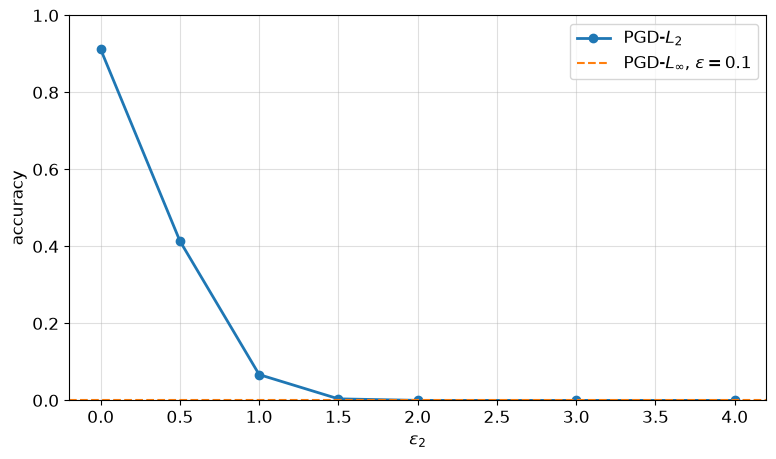

In [226]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=2.0, accuracy gap=0.000


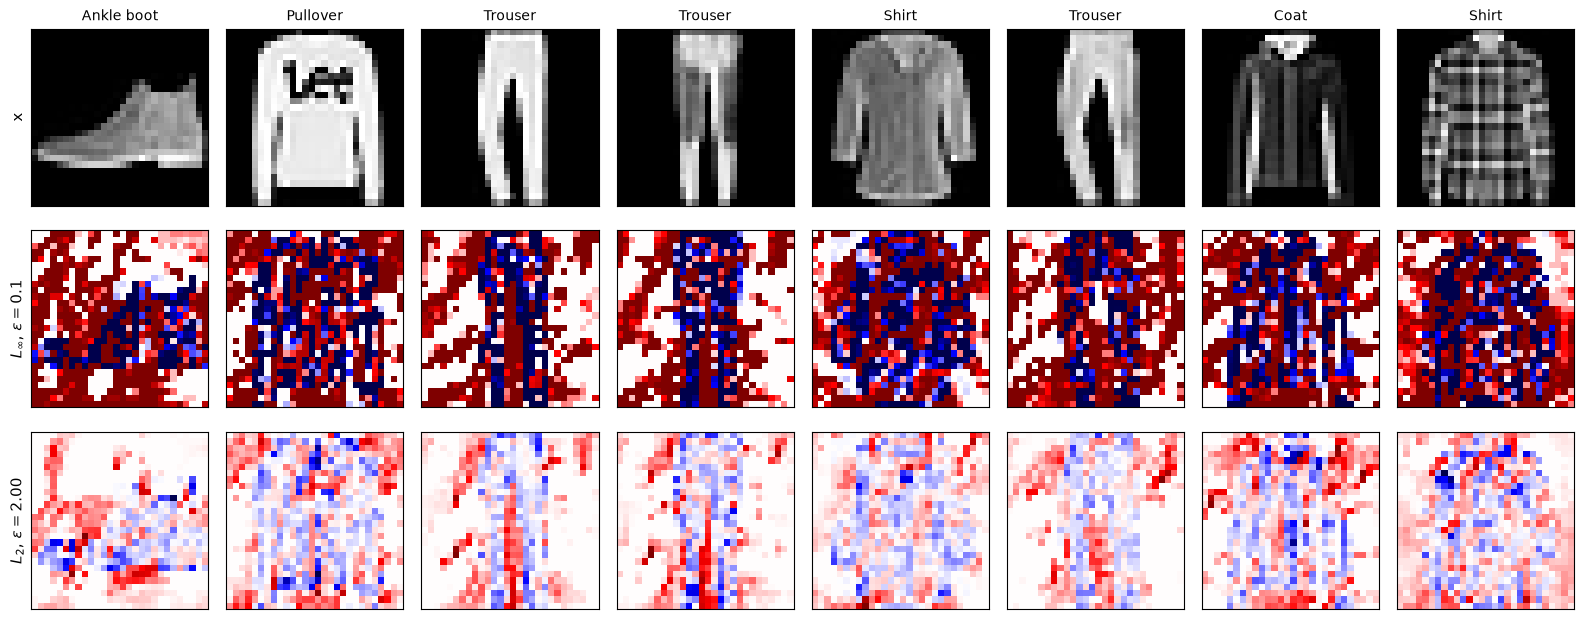

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.148
$L_2$, $\varepsilon=2.00$    L_inf = 0.387   L_2 = 1.987


In [227]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** 

Ближайшая $\varepsilon_2$ оказалась равна 2.0 (из посчитанных). $L_2$-норма самого $L_\infty$-возмущения равна 2.148 и это больше, чем у $L_2$-возмущения. На показанных изображениях наиболее сильные L2-возмущения заметны около контуров и отдельных деталей объектов, хотя изменения присутствуют и на фоне. Это связано с тем, что шаг атаки пропорционален нормированному градиенту: деление на общую L2-норму сохраняет относительные величины его компонент, поэтому пиксели с большим модулем градиента изменяются сильнее. Итоговая карта складывается из нескольких таких шагов с проекцией на допустимый шар и ограничением яркости диапазоном [0, 1].

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [230]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        random_start = True
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
        for _ in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)
            x_adv = x_adv.detach() - alpha * grad.sign()
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
        return x_adv.detach()


def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
    model.eval()
    result = torch.full((n_classes, n_classes), float("nan"), device="cpu")
    alpha = 2.5 * eps / steps

    for source in range(n_classes):
        indices = (y == source).nonzero(as_tuple=True)[0]
        if indices.numel() == 0:
            continue

        for target in range(n_classes):
            if target == source:
                continue

            hits = 0
            for batch_indices in indices.split(128):
                x_batch = x[batch_indices]
                targets = torch.full(
                    (len(x_batch),),
                    target,
                    dtype=torch.long,
                    device=x_batch.device,
                )
                x_adv = pgd_targeted(
                    model, x_batch, targets,
                    eps=eps, alpha=alpha, steps=steps,
                )

                with torch.no_grad():
                    predictions = model(x_adv).argmax(dim=1)
                    hits += (predictions == target).sum().item()

            result[source, target] = hits / indices.numel()

    return result

In [231]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.779; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.91 0.   0.02 0.02 0.   0.   0.06 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.02 0.   0.9  0.   0.03 0.   0.05 0.   0.   0.  ]
 [0.06 0.01 0.01 0.85 0.   0.   0.06 0.   0.   0.  ]
 [0.   0.   0.14 0.06 0.77 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.03 0.   0.07 0.03 0.02 0.   0.85 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.01 0.   0.   0.   0.   0.   0.   0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.05 0.   0.94]]


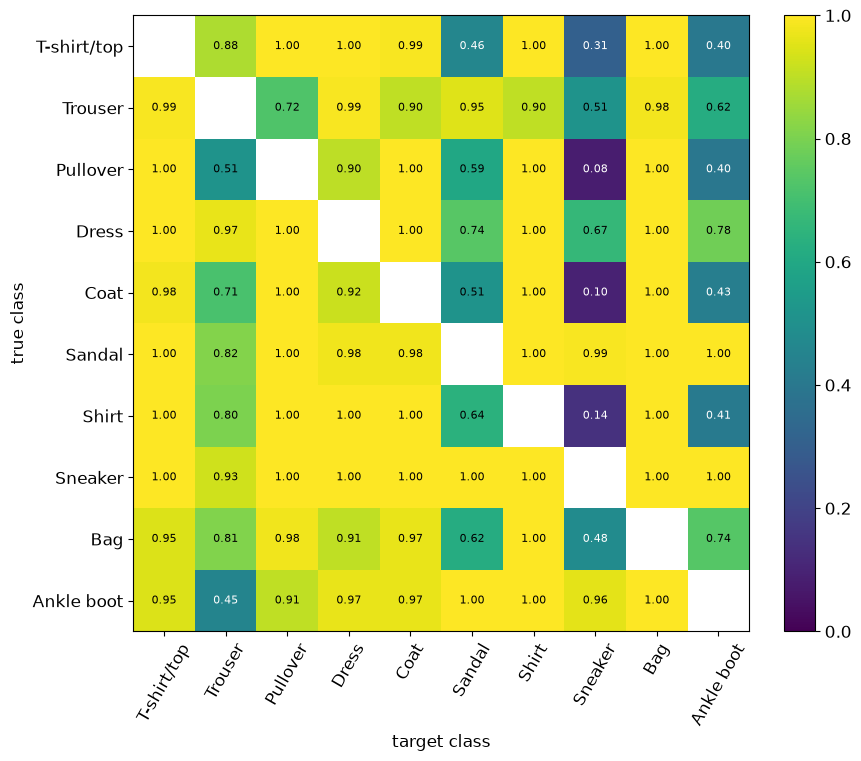

In [232]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** 

Есть классы, которые хорошо поддавались атаке: `Sandal`, `Sneaker`. Есть классы на которые было легко атаковать (делать их target): `Pullover`, `Dress`, `Bag`. Есть классы, которые тяжело поддаются атаки: `Pullover`, `Coat`. А в `Sneaker` было тяжело переделать. 

Матрица очевидно не симметрична, есть интересные пары, например `Coat` и `Sneaker`: `Coat` -> `Sneaker`: всего 10% удачных. `Sneaker` -> `Coat`: удачные - все.

Связь с ошибками без атаки есть, но не строгая. Например, модель и без атаки путает `Coat` с `Pullover` примерно в 14% случаев, а targeted-атака в этом направлении успешна почти в 100%. Однако `Sneaker` -> `Coat` тоже достигает почти 100%, хотя без атаки такая ошибка практически не встречается. Поэтому хорошая классификация чистых изображений ещё не означает устойчивости к специально подобранным возмущениям.

При этом для `Pullover` и `Coat` сложность атаки зависит от цели: их трудно перевести именно в `Sneaker` (8% и 10%), но во многие другие классы атака проходит почти всегда.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [ ]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.** 

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [233]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [236]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = dict(clean=[], fgsm=[], pgd=[])
    x_test, y_test = XF_test[:1000], YF_test[:1000]
    batch_size = 128
    n_batches = (len(XF_train) + batch_size - 1) // batch_size

    for epoch in range(epochs):
        batches = iterate_batches(
            XF_train, YF_train, batch_size, shuffle=True
        )

        for x, y in batches:
            optimizer.zero_grad(set_to_none=True)

            model.eval()
            x_adv = attack(model, x, y, eps).detach()

            model.train()
            loss = F.cross_entropy(model(x_adv), y)
            loss.backward()
            optimizer.step()

        optimizer.zero_grad(set_to_none=True)
        model.eval()

        history["clean"].append(
            attack_accuracy(model, x_test, y_test, batch_size=batch_size)
        )
        history["fgsm"].append(
            attack_accuracy(
                model, x_test, y_test,
                attack=fgsm_attack, batch_size=batch_size, eps=eps,
            )
        )
        history["pgd"].append(
            attack_accuracy(
                model, x_test, y_test,
                attack=pgd, batch_size=batch_size, eps=eps, steps=20,
            )
        )

        if log:
            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"clean: {history['clean'][-1]:.4f} | "
                f"FGSM: {history['fgsm'][-1]:.4f} | "
                f"PGD-20: {history['pgd'][-1]:.4f}"
            )

    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [237]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
Epoch 1/5 | clean: 0.7890 | FGSM: 0.6880 | PGD-20: 0.6610
Epoch 2/5 | clean: 0.7960 | FGSM: 0.6970 | PGD-20: 0.6660
Epoch 3/5 | clean: 0.8180 | FGSM: 0.7200 | PGD-20: 0.6950
Epoch 4/5 | clean: 0.8290 | FGSM: 0.7370 | PGD-20: 0.7000
Epoch 5/5 | clean: 0.8360 | FGSM: 0.7220 | PGD-20: 0.7030


In [238]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.912   0.112   0.000   0.000   0.000   0.000
PGD-AT       0.836   0.773   0.699   0.469   0.115   0.001


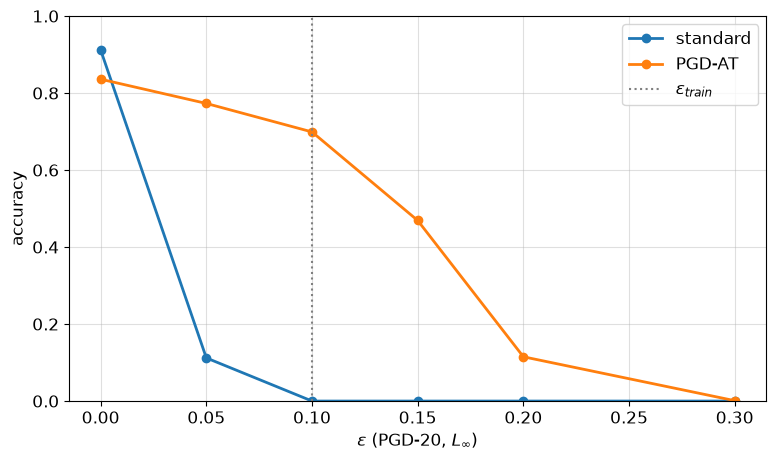

In [239]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** 

Чтобы определить чего стоила робастность, надо посмотреть какое качество имеет модель на чистных изображениях. На них мы adversarial training мы теряем около 7% accuracy, что на самом деле достаточно серьезно и нельзя считать просто шумом. Нам надо подбирать баланс робастости и качества в проде.

Когда $\epsilon$ на test становится больше, чем на train, то точность начинает падать значительно быстрее. Что в целом неудивительно, потому что модель раньше не видела такиъ изображений (они же меняются сильнее).

Вообще AT дороже обычного обучения примерно в (steps + 1) раз, что достаточно много.

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [240]:
def sanity_checks(model, x, y, eps):
    model.eval()
    correct = dict(fgsm=0, pgd20=0, pgd100_x5=0, eps_1=0)

    for start in range(0, len(x), 128):
        xb = x[start:start + 128]
        yb = y[start:start + 128]

        with torch.no_grad():
            clean_ok = model(xb).argmax(dim=1).eq(yb)

        x_adv = fgsm_attack(model, xb, yb, eps)
        with torch.no_grad():
            attack_ok = model(x_adv).argmax(dim=1).eq(yb)
            correct["fgsm"] += (clean_ok & attack_ok).sum().item()

        x_adv = pgd_attack(
            model, xb, yb, eps,
            alpha=2.5 * eps / 20,
            steps=20,
            random_start=True,
        )
        with torch.no_grad():
            attack_ok = model(x_adv).argmax(dim=1).eq(yb)
            correct["pgd20"] += (clean_ok & attack_ok).sum().item()

        survives = clean_ok.clone()
        for _ in range(5):
            x_adv = pgd_attack(
                model, xb, yb, eps,
                alpha=2.5 * eps / 100,
                steps=100,
                random_start=True,
            )
            with torch.no_grad():
                survives &= model(x_adv).argmax(dim=1).eq(yb)

        correct["pgd100_x5"] += survives.sum().item()

        x_adv = pgd_attack(
            model, xb, yb, eps=1.0,
            alpha=2.5 / 20,
            steps=20,
            random_start=True,
        )
        with torch.no_grad():
            attack_ok = model(x_adv).argmax(dim=1).eq(yb)
            correct["eps_1"] += (clean_ok & attack_ok).sum().item()

    return {name: count / len(x) for name, count in correct.items()}

In [243]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.055      0.000      0.000      0.000
PGD-AT                      0.723      0.695      0.695      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** 

У standard accuracy падает с 5.5% под FGSM до 0% под PGD. У PGD-AT снижение небольшое: с 72.3% до 69.5% — на 2.8 п.п.; PGD-100 с пятью рестартами результат не меняет. При $\varepsilon=1$ обе модели дают 0%. Явных аномалий нет; дополнительно стоит проверить разные размеры шага атаки и больше объектов.
Модель с высокой FGSM accuracy и почти нулевой PGD accuracy может пройти эти проверки: результаты не противоречат ожидаемому усилению атаки. Но робастной её считать нельзя — PGD успешно её атакует. Прохождение sanity checks само по себе не доказывает устойчивость или отсутствие gradient masking.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [247]:
def input_gradient(model, x, y):
    model.eval()
    x = x.detach().clone().requires_grad_(True)

    with torch.enable_grad():
        logits = model(x)
        selected = logits.gather(1, y[:, None]).sum()
        grad, = torch.autograd.grad(selected, x)

    return grad.abs().detach()


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [248]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5904015302658081, 'PGD-AT': 0.2434493452310562}

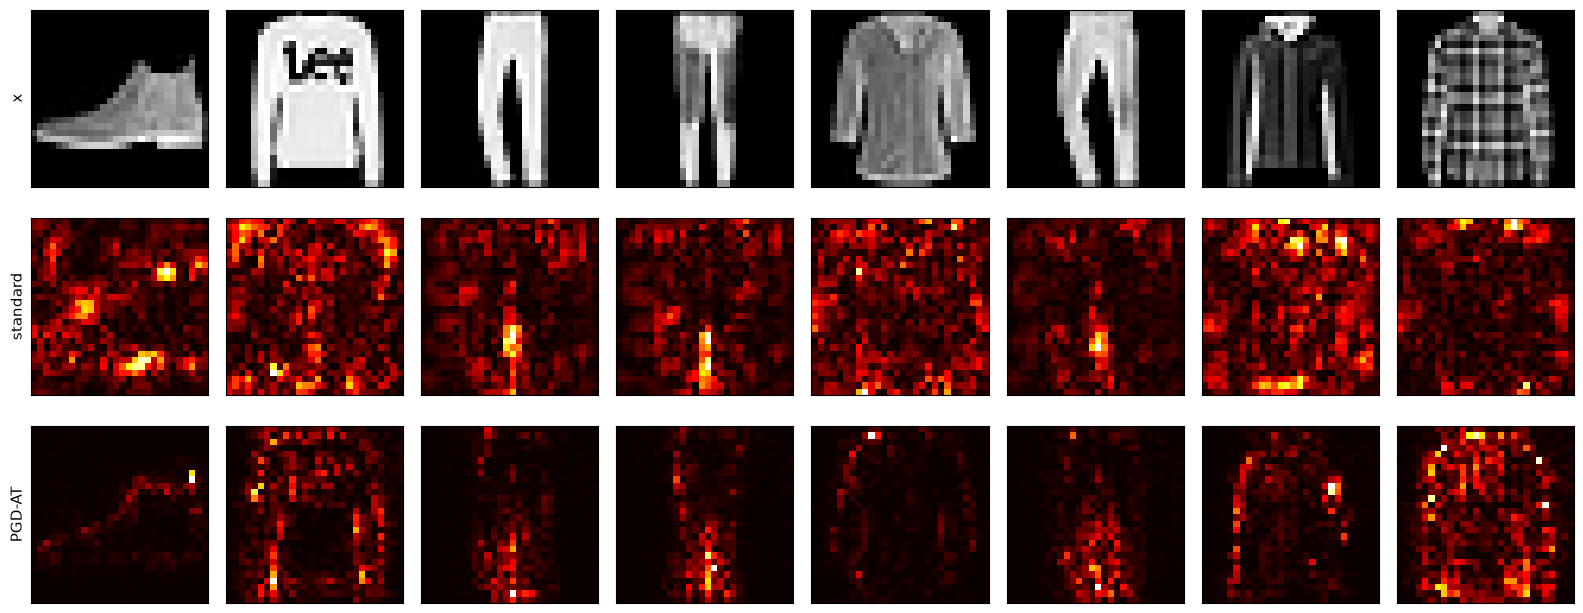

In [249]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** 

У стандартной модели карты более рассеянные: заметная чувствительность присутствует на фоне и у границ изображения. У PGD-AT градиент чаще сосредоточен на самом предмете и его деталях. Средняя доля массы градиента на фоне снизилась с 59% до 24% при этом фон занимает около 50% пикселей.

Это согласуется с результатами диагностики при ε = 0.1: PGD-20 accuracy стандартной модели равна 0%, а PGD-AT - 69.5%. Однако наблюдение не доказывает причинной связи между видом карты и устойчивостью.

Saliency показывает локальную чувствительность логита правильного класса, но не гарантирует, что предсказание сохранится при конечном допустимом возмущении. Поэтому понятная карта сама по себе не доказывает robustness: нужны отдельные проверки сильными атаками.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [250]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [ ]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        return torch.autograd.grad(
            outputs=grads,
            inputs=params,
            grad_outputs=v,
            retain_graph=True,
        )


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [ ]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

All assertions in cell 134 passed.


In [ ]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

lr=0.01, step=0, loss=0.4973, sharpness=4.44, boundary=200
lr=0.01, step=500, loss=0.2282, sharpness=6.33, boundary=200
lr=0.01, step=1000, loss=0.2026, sharpness=7.36, boundary=200
lr=0.01, step=1500, loss=0.1893, sharpness=8.07, boundary=200
lr=0.01, step=2000, loss=0.1806, sharpness=8.62, boundary=200
lr=0.01, step=2500, loss=0.1741, sharpness=9.15, boundary=200
lr=0.01, step=3000, loss=0.1690, sharpness=10.10, boundary=200
lr=0.05, step=0, loss=0.4973, sharpness=4.44, boundary=40
lr=0.05, step=500, loss=0.1741, sharpness=9.13, boundary=40
lr=0.05, step=1000, loss=0.1548, sharpness=14.77, boundary=40
lr=0.05, step=1500, loss=0.1420, sharpness=20.92, boundary=40
lr=0.05, step=2000, loss=0.1303, sharpness=28.04, boundary=40
lr=0.05, step=2500, loss=0.1196, sharpness=35.86, boundary=40
lr=0.05, step=3000, loss=0.1101, sharpness=38.19, boundary=40
lr=0.1, step=0, loss=0.4973, sharpness=4.44, boundary=20
lr=0.1, step=500, loss=0.1549, sharpness=14.74, boundary=20
lr=0.1, step=1000, loss=

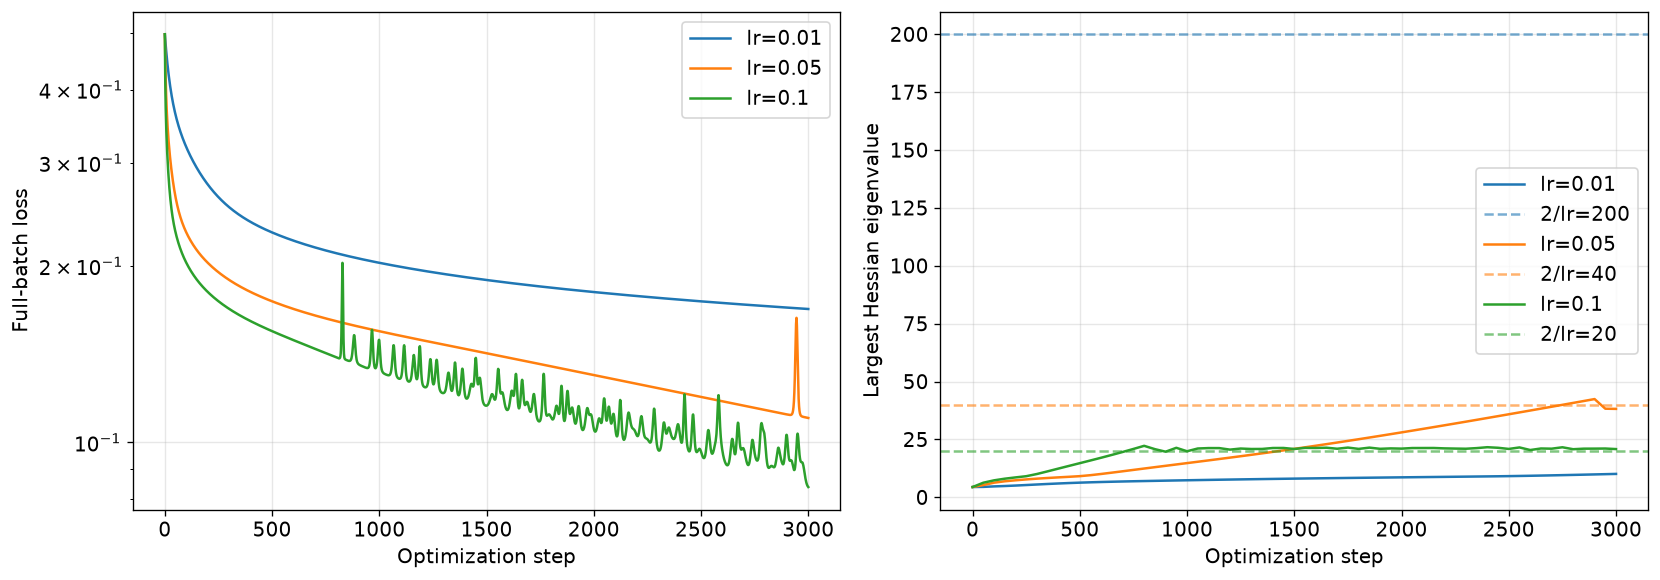

In [ ]:
if '7.1' in BONUS_TASKS:
    EOS_LRS = [0.01, 0.05, 0.1]
    eos_history = {}
    for eta in EOS_LRS:
        eos_model = make_tanh_mlp(seed=0)
        eos_params = list(eos_model.parameters())
        optimizer = torch.optim.SGD(eos_params, lr=eta, momentum=0)
        hist = dict(steps=[], loss=[], sharpness_steps=[], sharpness=[])
        eigenvector = None
        started = time.perf_counter()
        for step in range(EOS_STEPS + 1):
            optimizer.zero_grad(set_to_none=True)
            loss = mse_loss(eos_model)
            loss_value = loss.item()
            if not math.isfinite(loss_value):
                print(f'lr={eta}: non-finite loss at step {step}')
                break
            hist['steps'].append(step)
            hist['loss'].append(loss_value)
            if step % 50 == 0:
                sharpness, eigenvector = top_eigenvalue(
                    lambda: mse_loss(eos_model), eos_params, iters=20, v=eigenvector
                )
                hist['sharpness_steps'].append(step)
                hist['sharpness'].append(sharpness)
                if step % 500 == 0:
                    print(f'lr={eta}, step={step}, loss={loss_value:.4f}, sharpness={sharpness:.2f}, boundary={2 / eta:.0f}', flush=True)
            if step < EOS_STEPS:
                loss.backward()
                optimizer.step()
        eos_history[eta] = hist
        RUN_TIMES[f'eos_lr_{eta}_seconds'] = time.perf_counter() - started

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for eta, hist in eos_history.items():
        line, = axes[0].semilogy(hist['steps'], hist['loss'], label=f'lr={eta}')
        axes[1].plot(hist['sharpness_steps'], hist['sharpness'], color=line.get_color(), label=f'lr={eta}')
        axes[1].axhline(2 / eta, color=line.get_color(), linestyle='--', alpha=0.6, label=f'2/lr={2 / eta:.0f}')
    axes[0].set_ylabel('Full-batch loss')
    axes[1].set_ylabel('Largest Hessian eigenvalue')
    for ax in axes:
        ax.set_xlabel('Optimization step')
        ax.grid(True, alpha=0.3)
        ax.legend()
    fig.tight_layout()
    plt.show()
    for eta, hist in eos_history.items():
        print(f"lr={eta}: loss {hist['loss'][0]:.4f} -> {hist['loss'][-1]:.4f}, max sharpness/boundary={max(hist['sharpness']) * eta / 2:.3f}")

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.**

При $\eta=0.05$ sharpness приблизилась к границе $40$, при $\eta=0.1$ держалась около $20$ и немного превышала её. При $\eta=0.01$ до границы $200$ не дошла. Loss в итоге снизился с $0.50$ до $0.17$, $0.11$ и $0.08$ соответственно: приближение к границе не остановило обучение, но появились всплески loss, особенно при $\eta=0.1$.

У квадратичной функции гессиан фиксирован, а у сети меняется вместе с весами и может быть неопределённым. Поэтому локальная sharpness описывает текущую кривизну, но сама по себе не гарантирует дальнейшую динамику.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [ ]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        x_pad = F.pad(x, (padding, padding, padding, padding))
        batch, channels, height, width = x_pad.shape
        out_channels, _, kh, kw = weight.shape
        fft_shape = (height + kh - 1, width + kw - 1)
        x_freq = torch.fft.rfft2(x_pad, s=fft_shape)
        w_freq = torch.fft.rfft2(weight.flip((-2, -1)), s=fft_shape)
        x_freq = x_freq.reshape(batch, groups, channels // groups, *x_freq.shape[-2:])
        w_freq = w_freq.reshape(groups, out_channels // groups, channels // groups, *w_freq.shape[-2:])
        out_freq = torch.einsum('bgchw,gochw->bgohw', x_freq, w_freq)
        out = torch.fft.irfft2(out_freq, s=fft_shape)
        out = out.reshape(batch, out_channels, *fft_shape)
        out = out[:, :, kh - 1:height:stride, kw - 1:width:stride]
        if bias is not None:
            out = out + bias[None, :, None, None]
        return out

In [ ]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

All assertions in cell 141 passed.


**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.**

При stride $s$ остаётся примерно $1/s^2$ позиций valid-выхода, поэтому выбрасывается доля $1-1/s^2$. Точно для valid-карты $H_v\times W_v$ доля отброшенных позиций равна $1-\lceil H_v/s\rceil\lceil W_v/s\rceil/(H_vW_v)$; отдельно отбрасываются края полной свёртки. FFT может быть выгоднее для больших ядер и небольшого stride, когда стоимость преобразований окупается. При большом stride значительная часть работы FFT не используется, поэтому выигрыш не гарантирован.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [ ]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        transposed = M.shape[0] > M.shape[1]
        X = M.T if transposed else M
        X = X / X.norm().clamp_min(1e-7)
        a, b, c = coeffs
        for _ in range(steps):
            gram = X @ X.T
            X = a * X + (b * gram + c * (gram @ gram)) @ X
        return X.T if transposed else X


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))
            if any(p.ndim < 2 for group in self.param_groups for p in group['params']):
                raise ValueError('ConvMuon requires parameters with at least two dimensions')

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    state = self.state[p]
                    if not state:
                        state['momentum_buffer'] = torch.zeros_like(p)
                    buffer = state['momentum_buffer']
                    buffer.mul_(mu).add_(p.grad, alpha=1 - mu)
                    update = (1 - mu) * p.grad + mu * buffer
                    matrix = update.reshape(p.shape[0], -1)
                    scale = math.sqrt(max(1, matrix.shape[0] / matrix.shape[1]))
                    direction = newton_schulz(matrix).reshape_as(p)
                    p.add_(direction, alpha=-group['lr'] * scale)

In [ ]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

All assertions in cell 146 passed.


In [ ]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    set_seed(0)
    muon_model = ResNetCIFAR(20).to(device)
    conv_params = [p for p in muon_model.parameters() if p.ndim == 4]
    other_params = [p for p in muon_model.parameters() if p.ndim != 4]
    muon_optimizer = ConvMuon(conv_params, lr=MUON_LR)
    adam_optimizer = MyAdamW([
        dict(params=[p for p in other_params if p.ndim > 1], weight_decay=0.05),
        dict(params=[p for p in other_params if p.ndim <= 1], weight_decay=0.0),
    ], lr=LR)
    total_steps = EPOCHS * ((len(X_train) + 255) // 256)
    optimizers = [muon_optimizer, adam_optimizer]
    schedulers = [torch.optim.lr_scheduler.LambdaLR(
        opt, lambda step: cosine_lr(step, total_steps, min_ratio=0.0)
    ) for opt in optimizers]
    hist_muon = dict(train_loss=[], test_acc=[])
    started = time.perf_counter()
    for epoch in range(EPOCHS):
        muon_model.train()
        loss_sum = 0.0
        for xb, yb in iterate_batches(X_train, Y_train, 256, transform=normalize):
            for opt in optimizers:
                opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(muon_model(xb), yb)
            loss.backward()
            for opt, scheduler in zip(optimizers, schedulers):
                opt.step()
                scheduler.step()
            loss_sum += loss.item() * len(yb)
        hist_muon['train_loss'].append(loss_sum / len(X_train))
        hist_muon['test_acc'].append(accuracy(predict_logits(muon_model, X_test, batch_size=256, transform=normalize), Y_test))
        print(f"Muon epoch {epoch + 1}/{EPOCHS}: loss={hist_muon['train_loss'][-1]:.4f}, test={hist_muon['test_acc'][-1]:.4f}", flush=True)
    RUN_TIMES['cifar_muon_seconds'] = time.perf_counter() - started
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')


Muon epoch 1/20: loss=1.1598, test=0.5857
Muon epoch 2/20: loss=0.6674, test=0.7504
Muon epoch 3/20: loss=0.5060, test=0.7877
Muon epoch 4/20: loss=0.3981, test=0.8092
Muon epoch 5/20: loss=0.3128, test=0.8275
Muon epoch 6/20: loss=0.2415, test=0.8156
Muon epoch 7/20: loss=0.1796, test=0.8257
Muon epoch 8/20: loss=0.1313, test=0.8342
Muon epoch 9/20: loss=0.0922, test=0.8325
Muon epoch 10/20: loss=0.0626, test=0.8330
Muon epoch 11/20: loss=0.0406, test=0.8368
Muon epoch 12/20: loss=0.0289, test=0.8387
Muon epoch 13/20: loss=0.0175, test=0.8416
Muon epoch 14/20: loss=0.0103, test=0.8436
Muon epoch 15/20: loss=0.0058, test=0.8455
Muon epoch 16/20: loss=0.0031, test=0.8495
Muon epoch 17/20: loss=0.0016, test=0.8503
Muon epoch 18/20: loss=0.0010, test=0.8509
Muon epoch 19/20: loss=0.0008, test=0.8500
Muon epoch 20/20: loss=0.0007, test=0.8503
            train loss  test acc
AdamW           0.0139    0.8291
Muon            0.0007    0.8503


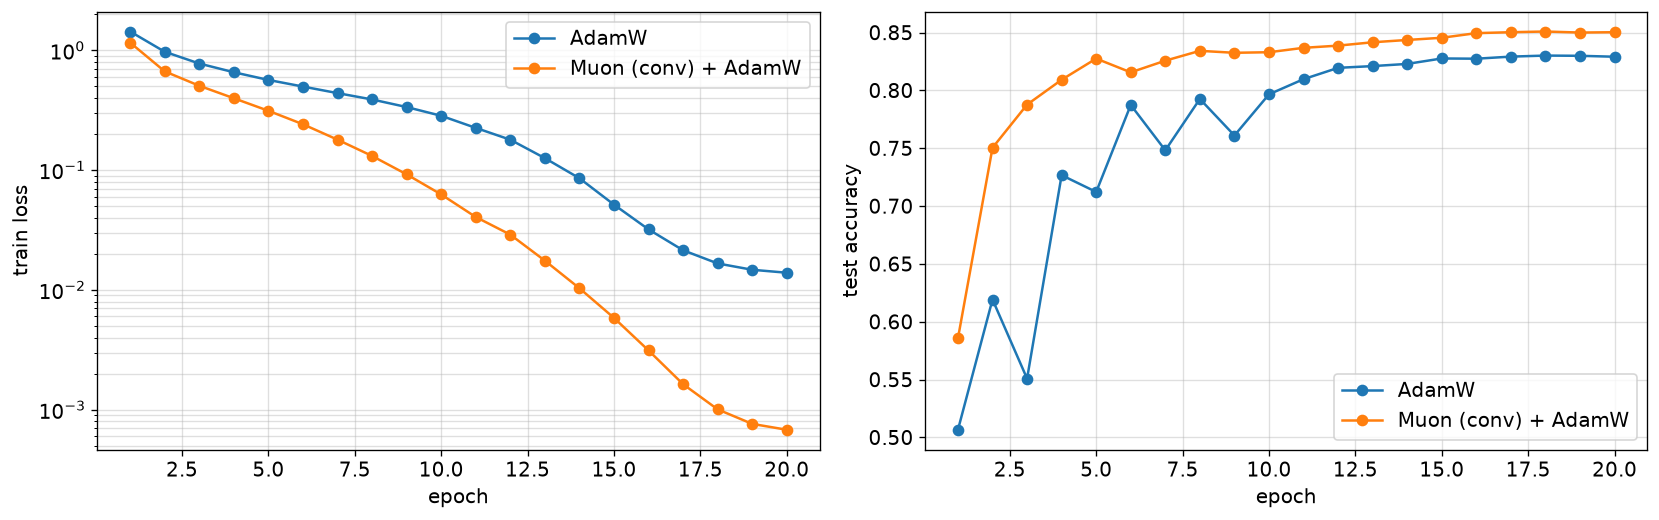

In [ ]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.**

В этом прогоне Muon быстрее снижал train loss по эпохам: итоговый loss $0.0007$ против $0.0139$ у AdamW. За те же $20$ эпох test accuracy получилась $85\%$ против $83\%$. По времени Muon оказался медленнее: $267$ секунд против $205$ у AdamW. Это сравнение при одинаковом числе шагов, а не одинаковом времени; один seed ещё не доказывает устойчивое преимущество.

AdamW хранит два момента, то есть два числа на параметр, Muon хранит один momentum. В FP32 это $8$ и $4$ байта соответственно, без весов, градиентов и временных тензоров. В нашей смешанной схеме остальные параметры всё ещё обновляются AdamW.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [ ]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [ ]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.924, 'L0, k=5': 0.6}
standard    0.924  0.882  0.838  0.770  0.600  0.360  0.108  0.036
PGD-AT      0.850  0.808  0.784  0.762  0.718  0.626  0.434  0.320


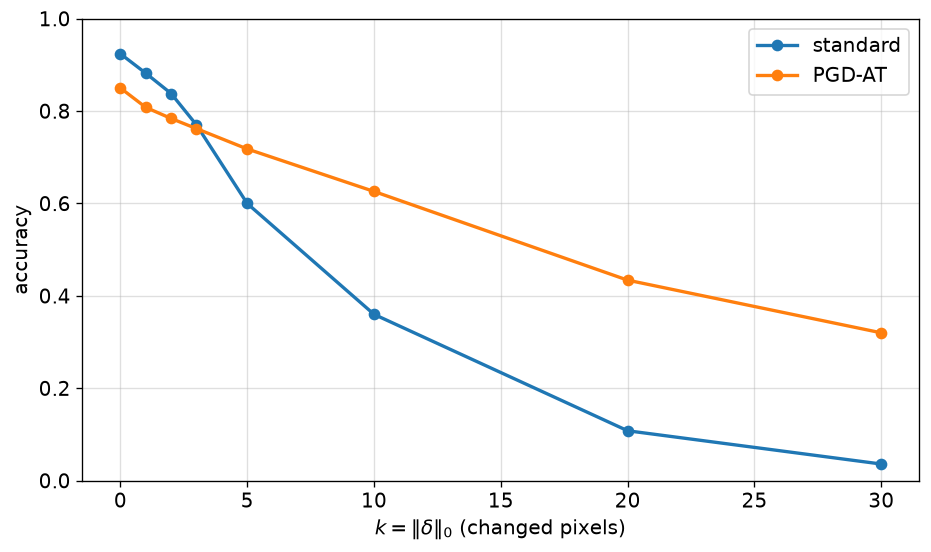

In [ ]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.**

В моём эксперименте помогает, особенно при большом числе изменённых пикселей: при $k=5$ accuracy $72\%$ против $60\%$, при $k=30$ уже $32\%$ против $4\%$. При этом без атаки у PGD-AT accuracy ниже: $85\%$ против $92\%$, поэтому на малых $k$ преимущество ещё не появляется.

Но гарантии защиты от $L_0$ тут нет. Замена одного пикселя с $0$ на $1$ имеет $L_\infty$-норму $1$, поэтому лежит вне шара с нашим $\varepsilon=0.1$, хотя меняется всего один пиксель.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [ ]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
Epoch 1/5 | clean: 0.7120 | FGSM: 0.6350 | PGD-20: 0.0480
Epoch 2/5 | clean: 0.6880 | FGSM: 0.7530 | PGD-20: 0.0000
Epoch 3/5 | clean: 0.6060 | FGSM: 0.9610 | PGD-20: 0.0000
Epoch 4/5 | clean: 0.6280 | FGSM: 0.9670 | PGD-20: 0.0000
Epoch 5/5 | clean: 0.5650 | FGSM: 0.9510 | PGD-20: 0.0000
FGSM-RS
Epoch 1/5 | clean: 0.7520 | FGSM: 0.6150 | PGD-20: 0.3710
Epoch 2/5 | clean: 0.7650 | FGSM: 0.6540 | PGD-20: 0.3850
Epoch 3/5 | clean: 0.8070 | FGSM: 0.6970 | PGD-20: 0.4490
Epoch 4/5 | clean: 0.8020 | FGSM: 0.7220 | PGD-20: 0.4340
Epoch 5/5 | clean: 0.8050 | FGSM: 0.7240 | PGD-20: 0.4470


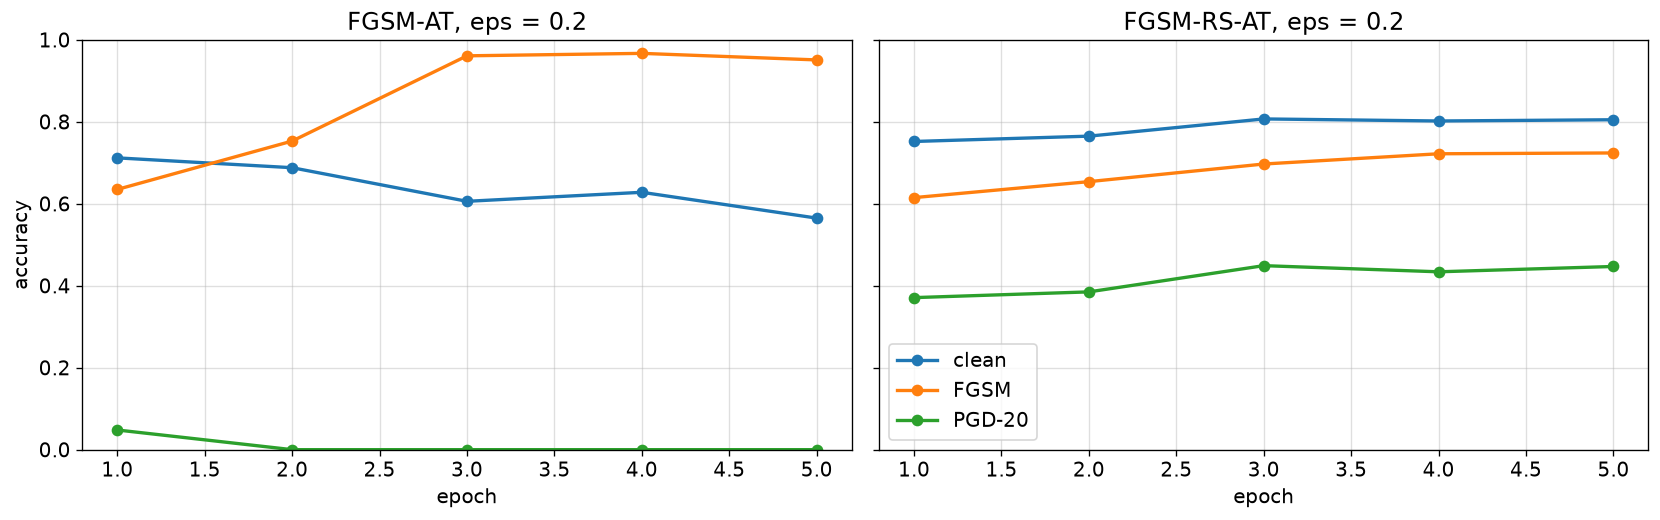

In [ ]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [ ]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.5625, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.69921875, 'pgd20': 0.43359375, 'pgd100_x5': 0.37890625, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.**

У FGSM PGD accuracy уже после первой эпохи была всего $5\%$, а после второй стала нулевой. При этом FGSM accuracy выросла до $95\%$: модель подстроилась под слабую атаку, реальной робастности нет. Это согласуется с catastrophic overfitting, но резкий переход внутри первой эпохи мы не измеряли.

Random start изменил картину: PGD accuracy держалась около $37$-$45\%$, обвала за пять эпох не было. На $256$ изображениях усиление PGD с $20$ шагов до $100$ шагов и пяти рестартов снизило accuracy с $43\%$ до $38\%$. У обычного FGSM обе оценки нулевые, при $\varepsilon=1$ обе модели тоже дали ноль.

В sanity checks FGSM accuracy ниже, чем на графике: там другая подвыборка и засчитываются только изображения, верные и до, и после атаки. Поэтому эти числа напрямую сравнивать нельзя.